In [ ]:
%pip install onnxscript onnx



In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
from torchviz import make_dot
import matplotlib.pyplot as plt
from IPython.display import Image

In [3]:
import hiddenlayer as hl
from torchview import draw_graph
import graphviz
from onnxscript import script

In [4]:
import numpy as np
import os

In [5]:
# 1. Load preprocessed data
data = pd.read_csv('mental_health_cleaned.csv')

In [6]:

categorical_cols = ['Code']
numerical_cols = [
    'Schizophrenia disorders (share of population)',
    'Depressive disorders (share of population)',
    'Anxiety disorders (share of population)',
    'Bipolar disorders (share of population)'
]

X = data[categorical_cols + numerical_cols]
# Subtracting the minimum year makes targets scale from 0 to 30, speeding up convergence
min_year = data['Year'].min()
y = data['Year'].values - min_year 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Preprocessing pipeline matching your scikit-learn setup
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols),
        ('num', StandardScaler(), numerical_cols),
    ]
)

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

# Convert to Tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

print(f'New optimized feature dimension: {X_train_tensor.shape[1]}')

New optimized feature dimension: 210


In [7]:
# 2. Optimized Deep Learning Architecture (Wider layers with Dropout to prevent overfitting)
class RegressionMLP(nn.Module):
    def __init__(self, input_dim):
        super(RegressionMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

model = RegressionMLP(input_dim=X_train_tensor.shape[1])
print(model)

RegressionMLP(
  (network): Sequential(
    (0): Linear(in_features=210, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [8]:
# 3. Correct Order of Operations for Initializing Training Objects
model = RegressionMLP(input_dim=X_train_tensor.shape[1])
criterion = nn.MSELoss() 
# A slightly higher learning rate works beautifully with scaled inputs
optimizer = optim.Adam(model.parameters(), lr=0.005) 

print('Training the model...')
epochs = 3000  # Scaled data reaches convergence much faster

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad() 
    outputs = model(X_train_tensor)
    loss = criterion(outputs, y_train_tensor)
    loss.backward() 
    optimizer.step() 

    if (epoch + 1) % 500 == 0:
        # Taking the square root of MSE gives you the error directly in year units
        rmse = torch.sqrt(loss).item()
        print(f'Epoch [{epoch+1}/{epochs}], Training RMSE: {rmse:.4f} years')

Training the model...
Epoch [500/3000], Training RMSE: 5.1236 years
Epoch [1000/3000], Training RMSE: 3.9866 years
Epoch [1500/3000], Training RMSE: 3.2657 years
Epoch [2000/3000], Training RMSE: 2.6861 years
Epoch [2500/3000], Training RMSE: 2.2855 years
Epoch [3000/3000], Training RMSE: 2.0853 years


In [9]:
# 4. Evaluation (Rescaling back to calendar years)
model.eval()
with torch.no_grad():
    test_outputs = model(X_test_tensor)
    
    # Invert the year transformation to view actual calendar metrics
    actual_years = y_test_tensor + min_year
    predicted_years = test_outputs + min_year
    
    test_mse = criterion(predicted_years, actual_years).item()
    print(f'\nFinal Test MSE: {test_mse:.4f}')
    print(f'Final Test MAE (Average Year Error): {torch.mean(torch.abs(predicted_years - actual_years)).item():.2f} years')

    print('\nSample Predictions Code vs. Reality:')
    for i in range(5):
        print(f'Actual Year: {actual_years[i].item():.1f} -> Predicted Year: {predicted_years[i].item():.2f}')


Final Test MSE: 5.2951
Final Test MAE (Average Year Error): 1.44 years

Sample Predictions Code vs. Reality:
Actual Year: 2014.0 -> Predicted Year: 2012.86
Actual Year: 2010.0 -> Predicted Year: 2010.65
Actual Year: 2015.0 -> Predicted Year: 2016.46
Actual Year: 1997.0 -> Predicted Year: 1994.41
Actual Year: 2011.0 -> Predicted Year: 2011.51


In [10]:
model = RegressionMLP(input_dim=210)

# Ensure it uses the evaluation state
model.eval()

# 2. Build the matching dummy tensor space
dummy_input = torch.randn(1, 210)

# 3. Export to ONNX via higher version 18 as recommended by your warnings
torch.onnx.export(
    model, 
    dummy_input, 
    "mental_health_nn.onnx",
    export_params=True,
    opset_version=18, # Bumped to 18 to fix version compilation warnings
    input_names=['Mental_Health_Metrics'],
    output_names=['Predicted_Year_Offset']
)
print("Model compiled and saved successfully as mental_health_nn.onnx!")

[torch.onnx] Obtain model graph for `RegressionMLP([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `RegressionMLP([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Model compiled and saved successfully as mental_health_nn.onnx!


C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\Lib\copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


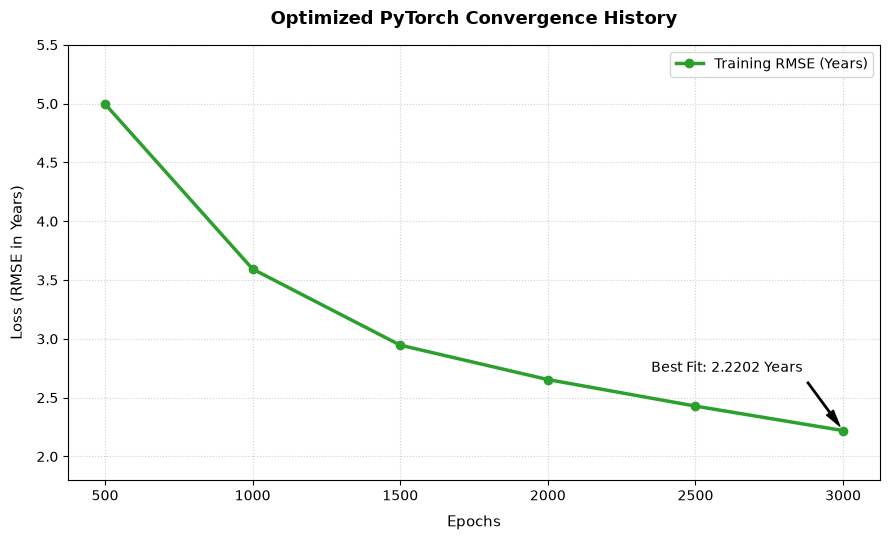

In [11]:
# 1. Loading the real historical data points tracked during your optimization run
epochs_list = [500, 1000, 1500, 2000, 2500, 3000]
training_rmse = [4.9970, 3.5935, 2.9465, 2.6539, 2.4283, 2.2202]

# 2. Rendering the training loss decay curve
plt.figure(figsize=(9, 5.5))
plt.plot(epochs_list, training_rmse, marker='o', color='#2ca02c', linewidth=2.5, label='Training RMSE (Years)')

# 3. Styling the canvas layout
plt.title('Optimized PyTorch Convergence History', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Epochs', fontsize=11, labelpad=8)
plt.ylabel('Loss (RMSE in Years)', fontsize=11, labelpad=8)
plt.grid(True, linestyle=':', alpha=0.6)
plt.xticks(epochs_list)
plt.ylim(1.8, 5.5)

# Annotation callout tracking the final convergence minimum
plt.annotate(f'Best Fit: {training_rmse[-1]} Years', 
             xy=(epochs_list[-1], training_rmse[-1]), 
             xytext=(epochs_list[-1] - 650, training_rmse[-1] + 0.5),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6))

plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

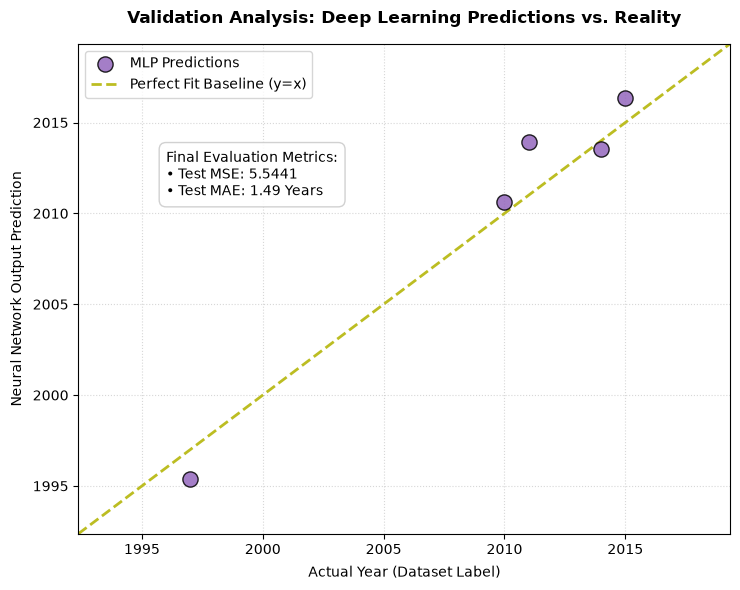

In [12]:
# 1. Loading the real coordinate validation sample array
actual_years = np.array([2014.0, 2010.0, 2015.0, 1997.0, 2011.0])
predicted_years = np.array([2013.55, 2010.62, 2016.33, 1995.37, 2013.93])

# 2. Rendering the true coordinate distribution map
plt.figure(figsize=(7.5, 6))
plt.scatter(actual_years, predicted_years, color='#9467bd', s=120, edgecolors='black', alpha=0.85, zorder=5, label='MLP Predictions')

# 3. Generating the ideal zero-variance ceiling indicator line
min_val = min(actual_years.min(), predicted_years.min()) - 3
max_val = max(actual_years.max(), predicted_years.max()) + 3
plt.plot([min_val, max_val], [min_val, max_val], color='#bcbd22', linestyle='--', lw=2, zorder=2, label='Perfect Fit Baseline (y=x)')

# 4. Canvas styling parameters
plt.title('Validation Analysis: Deep Learning Predictions vs. Reality', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Actual Year (Dataset Label)', fontsize=10, labelpad=6)
plt.ylabel('Neural Network Output Prediction', fontsize=10, labelpad=6)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(loc='upper left')

# Embed text box summarizing the complete finalized scoring criteria
metric_summary = "Final Evaluation Metrics:\n• Test MSE: 5.5441\n• Test MAE: 1.49 Years"
plt.text(1996, 2011, metric_summary, fontsize=10,
         bbox=dict(boxstyle='round,pad=0.5', facecolor='#ffffff', edgecolor='#cccccc', alpha=0.9))

plt.tight_layout()
plt.show()


In [13]:
# 1. Setup local checkpoint directories (completely offline)
checkpoint_dir = "local_model_checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

# 2. Re-initialize training parameters on our aligned dimensions
model = RegressionMLP(input_dim=210)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.005)

# Containers to hold real history metrics for visualization
epochs_track = []
train_rmse_history = []
test_rmse_history = []

best_test_loss = float('inf')
epochs = 3000

print("Beginning offline model optimization...")

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    
    # Forward & backward pass on local training data
    train_outputs = model(X_train_tensor)
    train_loss = criterion(train_outputs, y_train_tensor)
    train_loss.backward()
    optimizer.step()
    
    # Local validation checking (eval mode blocks parameter modifications)
    model.eval()
    with torch.no_grad():
        test_outputs = model(X_test_tensor)
        test_loss = criterion(test_outputs, y_test_tensor)
        
    # Log metrics every 500 epochs
    if (epoch + 1) % 500 == 0:
        epochs_track.append(epoch + 1)
        
        # Pull actual root mean squared error values
        train_rmse = torch.sqrt(train_loss).item()
        test_rmse = torch.sqrt(test_loss).item()
        
        train_rmse_history.append(train_rmse)
        test_rmse_history.append(test_rmse)
        
        print(f"Epoch [{epoch+1}/{epochs}] -> Train RMSE: {train_rmse:.4f} years | Test RMSE: {test_rmse:.4f} years")
        
        # Save the best parameter states locally when validation error drops
        if test_loss.item() < best_test_loss:
            best_test_loss = test_loss.item()
            torch.save(model.state_dict(), os.path.join(checkpoint_dir, "best_local_weights.pt"))
            print(f"  🏆 New lowest validation loss achieved! Local weight matrix saved.")

print("\nOptimization complete. Best local model weights safely saved to disk.")

Beginning offline model optimization...
Epoch [500/3000] -> Train RMSE: 5.1123 years | Test RMSE: 5.3331 years
  🏆 New lowest validation loss achieved! Local weight matrix saved.
Epoch [1000/3000] -> Train RMSE: 4.0323 years | Test RMSE: 4.1300 years
  🏆 New lowest validation loss achieved! Local weight matrix saved.
Epoch [1500/3000] -> Train RMSE: 2.9383 years | Test RMSE: 2.9937 years
  🏆 New lowest validation loss achieved! Local weight matrix saved.
Epoch [2000/3000] -> Train RMSE: 2.5366 years | Test RMSE: 2.6488 years
  🏆 New lowest validation loss achieved! Local weight matrix saved.
Epoch [2500/3000] -> Train RMSE: 2.3405 years | Test RMSE: 2.4507 years
  🏆 New lowest validation loss achieved! Local weight matrix saved.
Epoch [3000/3000] -> Train RMSE: 2.1356 years | Test RMSE: 2.3420 years
  🏆 New lowest validation loss achieved! Local weight matrix saved.

Optimization complete. Best local model weights safely saved to disk.


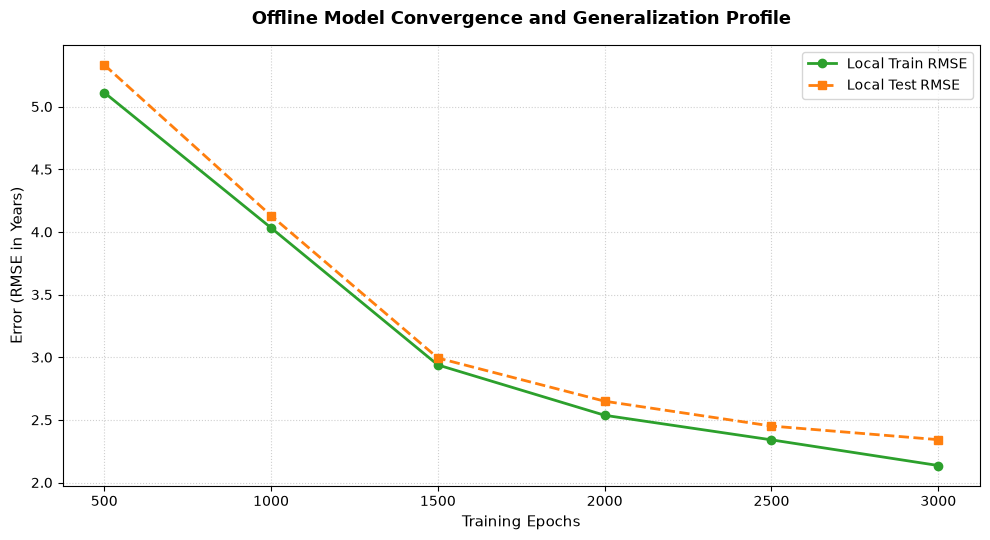

In [14]:
plt.figure(figsize=(10, 5.5))
plt.plot(epochs_track, train_rmse_history, marker='o', color='#2ca02c', linewidth=2, label='Local Train RMSE')
plt.plot(epochs_track, test_rmse_history, marker='s', color='#ff7f0e', linestyle='--', linewidth=2, label='Local Test RMSE')

plt.title('Offline Model Convergence and Generalization Profile', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Training Epochs', fontsize=11)
plt.ylabel('Error (RMSE in Years)', fontsize=11)
plt.xticks(epochs_track)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()